# California Housing Price Prediction: OLS, Ridge & Lasso Regression

**Objective:** Engineer interaction features, impute missing values, address multicollinearity, and compare Ordinary Least Squares (OLS), Ridge (L2), and Lasso (L1) regression models using RMSE, MAE, and $R^2$ scores.


## 1. Load California Housing Dataset & Inspect Missing Values


In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Provided California Housing dataset snippet (filters truncated trailing row if present)
raw_csv = """longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
-122.25,37.85,52.0,919.0,213.0,413.0,193.0,4.0368,269700.0,NEAR BAY
-122.25,37.84,52.0,2535.0,489.0,1094.0,514.0,3.6591,299200.0,NEAR BAY
-122.25,37.84,52.0,3104.0,687.0,1157.0,647.0,3.12,241400.0,NEAR BAY
-122.26,37.84,42.0,2555.0,665.0,1206.0,595.0,2.0804,226700.0,NEAR BAY
-122.25,37.84,52.0,3549.0,707.0,1551.0,714.0,3.6912,261100.0,NEAR BAY
-122.26,37.85,52.0,2202.0,434.0,910.0,402.0,3.2031,281500.0,NEAR BAY
-122.26,37.85,52.0,3503.0,752.0,1504.0,734.0,3.2705,241800.0,NEAR BAY
-122.26,37.85,52.0,2491.0,474.0,1098.0,468.0,3.075,213500.0,NEAR BAY
-122.26,37.84,52.0,696.0,191.0,345.0,174.0,2.6736,191300.0,NEAR BAY
-122.26,37.85,52.0,2643.0,626.0,1212.0,620.0,1.9167,159200.0,NEAR BAY
-122.26,37.85,50.0,1120.0,283.0,697.0,264.0,2.125,140000.0,NEAR BAY
-122.27,37.85,52.0,1966.0,347.0,793.0,331.0,2.775,152500.0,NEAR BAY
-122.27,37.85,52.0,1228.0,293.0,648.0,303.0,2.1202,155500.0,NEAR BAY
-122.26,37.84,50.0,2239.0,455.0,990.0,419.0,1.9911,158700.0,NEAR BAY
-122.27,37.84,52.0,1503.0,298.0,690.0,275.0,2.6033,162900.0,NEAR BAY
-122.27,37.85,40.0,751.0,184.0,409.0,166.0,1.3578,147500.0,NEAR BAY
-122.27,37.85,42.0,1639.0,367.0,929.0,366.0,1.7135,159800.0,NEAR BAY
-122.27,37.84,52.0,2436.0,541.0,1015.0,478.0,1.725,113900.0,NEAR BAY
-122.27,37.84,52.0,1688.0,337.0,853.0,325.0,2.1806,99700.0,NEAR BAY
-122.27,37.84,52.0,2224.0,437.0,1006.0,422.0,2.6,132600.0,NEAR BAY
-122.28,37.85,41.0,535.0,123.0,317.0,119.0,2.4038,107500.0,NEAR BAY
-122.28,37.85,49.0,1130.0,244.0,607.0,239.0,2.4597,93800.0,NEAR BAY
-122.28,37.85,52.0,1898.0,421.0,1102.0,397.0,1.808,105500.0,NEAR BAY
-122.28,37.84,50.0,2082.0,492.0,1131.0,473.0,1.6424,108900.0,NEAR BAY
-122.28,37.84,52.0,729.0,160.0,395.0,155.0,1.6875,132000.0,NEAR BAY
-122.28,37.84,49.0,1916.0,447.0,863.0,378.0,1.9274,122300.0,NEAR BAY
-122.28,37.84,52.0,2153.0,481.0,1168.0,441.0,1.9615,115200.0,NEAR BAY
-122.27,37.84,48.0,1922.0,409.0,1026.0,335.0,1.7969,110400.0,NEAR BAY
-122.27,37.83,49.0,1655.0,366.0,754.0,329.0,1.375,104900.0,NEAR BAY
-122.27,37.83,51.0,2665.0,574.0,1258.0,536.0,2.7303,109700.0,NEAR BAY
-122.27,37.83,49.0,1215.0,282.0,570.0,264.0,1.4861,97200.0,NEAR BAY
-122.27,37.83,48.0,1798.0,432.0,987.0,374.0,1.0972,104500.0,NEAR BAY
-122.28,37.83,52.0,1511.0,390.0,901.0,403.0,1.4103,103900.0,NEAR BAY
-122.26,37.83,52.0,1470.0,330.0,689.0,309.0,3.48,191400.0,NEAR BAY
-122.26,37.83,52.0,2432.0,715.0,1377.0,696.0,2.5898,176000.0,NEAR BAY
-122.26,37.83,52.0,1665.0,419.0,946.0,395.0,2.0978,155400.0,NEAR BAY
-122.26,37.83,51.0,936.0,311.0,517.0,249.0,1.2852,150000.0,NEAR BAY
-122.26,37.84,49.0,713.0,202.0,462.0,189.0,1.025,118800.0,NEAR BAY
-122.26,37.84,52.0,950.0,202.0,467.0,198.0,3.9643,188800.0,NEAR BAY
-122.26,37.83,52.0,1443.0,311.0,660.0,292.0,3.0125,184400.0,NEAR BAY
-122.26,37.83,52.0,1656.0,420.0,718.0,382.0,2.6768,182300.0,NEAR BAY
-122.26,37.83,50.0,1125.0,322.0,616.0,304.0,2.026,142500.0,NEAR BAY
-122.27,37.82,43.0,1007.0,312.0,558.0,253.0,1.7348,137500.0,NEAR BAY
-122.26,37.82,40.0,624.0,195.0,423.0,160.0,0.9506,187500.0,NEAR BAY
-122.27,37.82,40.0,946.0,375.0,700.0,352.0,1.775,112500.0,NEAR BAY
-122.27,37.82,21.0,896.0,453.0,735.0,438.0,0.9218,171900.0,NEAR BAY
-122.27,37.82,43.0,1868.0,456.0,1061.0,407.0,1.5045,93800.0,NEAR BAY
-122.27,37.82,41.0,3221.0,853.0,1959.0,720.0,1.1108,97500.0,NEAR BAY
-122.27,37.82,52.0,1630.0,456.0,1162.0,400.0,1.2475,104200.0,NEAR BAY
-122.28,37.82,52.0,1170.0,235.0,701.0,233.0,1.6098,87500.0,NEAR BAY
-122.28,37.82,52.0,945.0,243.0,576.0,220.0,1.4113,83100.0,NEAR BAY
-122.28,37.82,52.0,1238.0,288.0,622.0,259.0,1.5057,87500.0,NEAR BAY
-122.28,37.82,52.0,1489.0,335.0,728.0,244.0,0.8172,85300.0,NEAR BAY
-122.28,37.82,52.0,1387.0,341.0,1074.0,304.0,1.2171,80300.0,NEAR BAY
-122.29,37.82,2.0,158.0,43.0,94.0,57.0,2.5625,60000.0,NEAR BAY
-122.29,37.83,52.0,1121.0,211.0,554.0,187.0,3.3929,75700.0,NEAR BAY
-122.29,37.82,49.0,135.0,29.0,86.0,23.0,6.1183,75000.0,NEAR BAY
-122.29,37.81,50.0,760.0,190.0,377.0,122.0,0.9011,86100.0,NEAR BAY
-122.3,37.81,52.0,1224.0,237.0,521.0,159.0,1.191,76100.0,NEAR BAY
-122.3,37.81,48.0,828.0,182.0,392.0,133.0,2.5938,73500.0,NEAR BAY
-122.3,37.81,52.0,1010.0,209.0,604.0,187.0,1.1667,78400.0,NEAR BAY
-122.3,37.81,48.0,1455.0,354.0,788.0,332.0,0.8056,84400.0,NEAR BAY
-122.29,37.8,52.0,1027.0,244.0,492.0,147.0,2.6094,81300.0,NEAR BAY
-122.3,37.81,52.0,572.0,109.0,274.0,82.0,1.8516,85000.0,NEAR BAY
-122.29,37.81,46.0,2801.0,644.0,1823.0,611.0,0.9802,129200.0,NEAR BAY
-122.29,37.81,26.0,768.0,152.0,392.0,127.0,1.7719,82500.0,NEAR BAY
-122.29,37.81,46.0,935.0,297.0,582.0,277.0,0.7286,95200.0,NEAR BAY
-122.29,37.81,49.0,844.0,204.0,560.0,152.0,1.75,75000.0,NEAR BAY
-122.29,37.81,46.0,12.0,4.0,18.0,7.0,0.4999,67500.0,NEAR BAY
-122.29,37.81,20.0,835.0,161.0,290.0,133.0,2.483,137500.0,NEAR BAY
-122.28,37.81,17.0,1237.0,462.0,762.0,439.0,0.9241,177500.0,NEAR BAY
-122.28,37.81,36.0,2914.0,562.0,1236.0,509.0,2.4464,102100.0,NEAR BAY
-122.28,37.81,19.0,1207.0,243.0,721.0,207.0,1.1111,108300.0,NEAR BAY
-122.29,37.81,23.0,1745.0,374.0,1054.0,325.0,0.8026,112500.0,NEAR BAY
-122.28,37.8,38.0,684.0,176.0,344.0,155.0,2.0114,131300.0,NEAR BAY
-122.28,37.81,17.0,924.0,289.0,609.0,289.0,1.5,162500.0,NEAR BAY
-122.27,37.81,52.0,210.0,56.0,183.0,56.0,1.1667,112500.0,NEAR BAY
-122.28,37.81,52.0,340.0,97.0,200.0,87.0,1.5208,112500.0,NEAR BAY
-122.28,37.81,52.0,386.0,164.0,346.0,155.0,0.8075,137500.0,NEAR BAY
-122.28,37.81,35.0,948.0,184.0,467.0,169.0,1.8088,118800.0,NEAR BAY
-122.28,37.81,52.0,773.0,143.0,377.0,115.0,2.4083,98200.0,NEAR BAY
-122.27,37.81,40.0,880.0,451.0,582.0,380.0,0.977,118800.0,NEAR BAY
-122.27,37.81,10.0,875.0,348.0,546.0,330.0,0.76,162500.0,NEAR BAY
-122.27,37.8,10.0,105.0,42.0,125.0,39.0,0.9722,137500.0,NEAR BAY
-122.27,37.8,52.0,249.0,78.0,396.0,85.0,1.2434,500001.0,NEAR BAY
-122.27,37.8,16.0,994.0,392.0,800.0,362.0,2.0938,162500.0,NEAR BAY
-122.28,37.8,52.0,215.0,87.0,904.0,88.0,0.8668,137500.0,NEAR BAY
-122.28,37.8,52.0,96.0,31.0,191.0,34.0,0.75,162500.0,NEAR BAY
-122.27,37.79,27.0,1055.0,347.0,718.0,302.0,2.6354,187500.0,NEAR BAY
-122.27,37.8,39.0,1715.0,623.0,1327.0,467.0,1.8477,179200.0,NEAR BAY
-122.26,37.8,36.0,5329.0,2477.0,3469.0,2323.0,2.0096,130000.0,NEAR BAY
-122.26,37.82,31.0,4596.0,1331.0,2048.0,1180.0,2.8345,183800.0,NEAR BAY
-122.26,37.81,29.0,335.0,107.0,202.0,91.0,2.0062,125000.0,NEAR BAY
-122.26,37.82,22.0,3682.0,1270.0,2024.0,1250.0,1.2185,170000.0,NEAR BAY
-122.26,37.82,37.0,3633.0,1085.0,1838.0,980.0,2.6104,193100.0,NEAR BAY
-122.25,37.81,29.0,4656.0,1414.0,2304.0,1250.0,2.4912,257800.0,NEAR BAY
-122.25,37.81,28.0,5806.0,1603.0,2563.0,1497.0,3.2177,273400.0,NEAR BAY
-122.25,37.81,39.0,854.0,242.0,389.0,228.0,3.125,237500.0,NEAR BAY
-122.25,37.81,52.0,2155.0,701.0,895.0,613.0,2.5795,350000.0,NEAR BAY
-122.26,37.81,34.0,5871.0,1914.0,2689.0,1789.0,2.8406,335700.0,NEAR BAY
-122.24,37.82,52.0,1509.0,225.0,674.0,244.0,4.9306,313400.0,NEAR BAY
-122.24,37.81,52.0,2026.0,482.0,709.0,456.0,3.2727,268500.0,NEAR BAY
-122.25,37.81,52.0,1758.0,460.0,686.0,422.0,3.1691,259400.0,NEAR BAY
-122.24,37.82,52.0,3481.0,751.0,1444.0,718.0,3.9,275700.0,NEAR BAY
-122.25,37.82,28.0,3337.0,855.0,1520.0,802.0,3.9063,225000.0,NEAR BAY
-122.25,37.82,52.0,1424.0,289.0,550.0,253.0,5.0917,262500.0,NEAR BAY
-122.25,37.82,32.0,3809.0,1098.0,1806.0,1022.0,2.6429,218500.0,NEAR BAY
-122.25,37.82,26.0,3959.0,1196.0,1749.0,1217.0,3.0233,255000.0,NEAR BAY
-122.25,37.83,52.0,2376.0,559.0,939.0,519.0,3.1484,224100.0,NEAR BAY
-122.25,37.83,35.0,1613.0,428.0,675.0,422.0,3.4722,243100.0,NEAR BAY
-122.25,37.83,52.0,1279.0,287.0,534.0,291.0,3.1429,231600.0,NEAR BAY
-122.25,37.83,28.0,5022.0,1750.0,2558.0,1661.0,2.4234,218500.0,NEAR BAY
-122.25,37.83,52.0,4190.0,1105.0,1786.0,1037.0,3.0897,234100.0,NEAR BAY
-122.23,37.84,50.0,2515.0,399.0,970.0,373.0,5.8596,327600.0,NEAR BAY
-122.23,37.84,47.0,3175.0,454.0,1098.0,485.0,5.2868,347600.0,NEAR BAY
-122.24,37.83,41.0,2576.0,406.0,794.0,376.0,5.956,366100.0,NEAR BAY
-122.24,37.85,37.0,334.0,54.0,98.0,47.0,4.9643,335000.0,NEAR BAY
-122.23,37.85,52.0,2800.0,411.0,1061.0,403.0,6.3434,373600.0,NEAR BAY
-122.24,37.84,52.0,3529.0,574.0,1177.0,555.0,5.1773,389500.0,NEAR BAY
-122.24,37.85,52.0,2612.0,365.0,901.0,367.0,7.2354,391100.0,NEAR BAY
-122.22,37.85,28.0,5287.0,1048.0,2031.0,956.0,5.457,337300.0,NEAR BAY
-122.22,37.84,50.0,2935.0,473.0,1031.0,479.0,7.5,295200.0,NEAR BAY
-122.21,37.84,44.0,3424.0,597.0,1358.0,597.0,6.0194,292300.0,NEAR BAY
-122.21,37.83,40.0,4991.0,674.0,1616.0,654.0,7.5544,411500.0,NEAR BAY
-122.2,37.84,30.0,2211.0,346.0,844.0,343.0,6.0666,311500.0,NEAR BAY
-122.21,37.84,34.0,3038.0,490.0,1140.0,496.0,7.0548,325900.0,NEAR BAY
-122.19,37.84,18.0,1617.0,210.0,533.0,194.0,11.6017,392600.0,NEAR BAY
-122.2,37.84,35.0,2865.0,460.0,1072.0,443.0,7.4882,319300.0,NEAR BAY
-122.21,37.83,34.0,5065.0,788.0,1627.0,766.0,6.8976,333300.0,NEAR BAY
-122.19,37.83,28.0,1326.0,184.0,463.0,190.0,8.2049,335200.0,NEAR BAY
-122.2,37.83,26.0,1589.0,223.0,542.0,211.0,8.401,351200.0,NEAR BAY
-122.19,37.83,29.0,1791.0,271.0,661.0,269.0,6.8538,368900.0,NEAR BAY
-122.19,37.82,32.0,1835.0,264.0,635.0,263.0,8.317,365900.0,NEAR BAY
-122.2,37.82,37.0,1229.0,181.0,420.0,176.0,7.0175,366700.0,NEAR BAY
-122.2,37.82,39.0,3770.0,534.0,1265.0,500.0,6.3302,362800.0,NEAR BAY
-122.18,37.81,30.0,292.0,38.0,126.0,52.0,6.3624,483300.0,NEAR BAY
-122.21,37.82,52.0,2375.0,333.0,813.0,350.0,7.0549,331400.0,NEAR BAY
-122.2,37.81,45.0,2964.0,436.0,1067.0,426.0,6.7851,323500.0,NEAR BAY
-122.21,37.8,50.0,2833.0,605.0,1260.0,552.0,2.8929,216700.0,NEAR BAY
-122.21,37.8,38.0,2254.0,535.0,951.0,487.0,3.0812,233100.0,NEAR BAY
-122.21,37.81,52.0,1389.0,212.0,510.0,224.0,5.2402,296400.0,NEAR BAY
-122.22,37.81,52.0,1971.0,335.0,765.0,308.0,6.5217,273700.0,NEAR BAY
-122.22,37.8,52.0,2183.0,465.0,1129.0,460.0,3.2632,227700.0,NEAR BAY
-122.22,37.8,52.0,2286.0,464.0,1073.0,441.0,3.0298,199600.0,NEAR BAY
-122.22,37.8,52.0,2721.0,541.0,1185.0,515.0,4.5428,239800.0,NEAR BAY
-122.22,37.81,52.0,2024.0,339.0,756.0,340.0,4.072,270100.0,NEAR BAY
-122.22,37.81,52.0,2944.0,536.0,1034.0,521.0,5.3509,302100.0,NEAR BAY
-122.23,37.8,52.0,2033.0,486.0,787.0,459.0,3.1603,269500.0,NEAR BAY
-122.23,37.81,52.0,1433.0,229.0,612.0,213.0,4.7708,314700.0,NEAR BAY
-122.22,37.81,52.0,2927.0,402.0,1021.0,380.0,8.1564,390100.0,NEAR BAY
-122.23,37.81,52.0,2315.0,292.0,861.0,258.0,8.8793,410300.0,NEAR BAY
-122.24,37.81,52.0,2485.0,313.0,953.0,327.0,6.8591,352400.0,NEAR BAY
-122.24,37.81,52.0,1490.0,238.0,634.0,256.0,6.0302,287300.0,NEAR BAY
-122.23,37.81,52.0,2814.0,365.0,878.0,352.0,7.508,348700.0,NEAR BAY
-122.24,37.81,52.0,2093.0,550.0,918.0,483.0,2.7477,243800.0,NEAR BAY
-122.24,37.8,52.0,888.0,168.0,360.0,175.0,2.1944,211500.0,NEAR BAY
-122.25,37.8,52.0,2087.0,510.0,1197.0,488.0,3.0149,218400.0,NEAR BAY
-122.24,37.81,52.0,2513.0,502.0,1048.0,518.0,3.675,269900.0,NEAR BAY
-122.25,37.81,46.0,3232.0,835.0,1373.0,747.0,3.225,218800.0,NEAR BAY
-122.25,37.8,42.0,4120.0,1065.0,1715.0,1015.0,2.9345,225000.0,NEAR BAY
-122.25,37.8,43.0,2364.0,792.0,1359.0,722.0,2.1429,250000.0,NEAR BAY
-122.25,37.8,41.0,1471.0,469.0,1062.0,413.0,1.6121,171400.0,NEAR BAY
-122.25,37.8,29.0,2468.0,864.0,1335.0,773.0,1.3929,193800.0,NEAR BAY
-122.24,37.79,27.0,1632.0,492.0,1171.0,429.0,2.3173,125000.0,NEAR BAY
-122.25,37.79,45.0,1786.0,526.0,1475.0,460.0,1.7772,97500.0,NEAR BAY
-122.25,37.79,50.0,629.0,188.0,742.0,196.0,2.6458,125000.0,NEAR BAY
-122.25,37.79,52.0,1339.0,391.0,1086.0,363.0,2.181,138800.0,NEAR BAY
-122.25,37.8,36.0,1678.0,606.0,1645.0,543.0,2.2303,116700.0,NEAR BAY
-122.25,37.8,43.0,2344.0,647.0,1710.0,644.0,1.6504,151800.0,NEAR BAY
-122.24,37.8,52.0,996.0,228.0,731.0,228.0,2.2697,127000.0,NEAR BAY
-122.24,37.8,52.0,1591.0,373.0,1118.0,347.0,2.1563,128600.0,NEAR BAY
-122.24,37.8,52.0,1586.0,398.0,1006.0,335.0,2.1348,140600.0,NEAR BAY
-122.24,37.8,47.0,2046.0,588.0,1213.0,554.0,2.6292,182700.0,NEAR BAY
-122.23,37.8,52.0,1192.0,289.0,772.0,257.0,2.3833,146900.0,NEAR BAY
-122.24,37.8,52.0,1803.0,420.0,1321.0,401.0,2.957,122800.0,NEAR BAY
-122.24,37.8,49.0,2838.0,749.0,1487.0,677.0,2.5238,169300.0,NEAR BAY
-122.23,37.8,52.0,783.0,184.0,488.0,186.0,1.9375,126600.0,NEAR BAY
-122.23,37.8,51.0,1590.0,414.0,949.0,392.0,1.9028,127900.0,NEAR BAY
-122.23,37.8,50.0,1746.0,480.0,1149.0,415.0,2.25,123500.0,NEAR BAY
-122.23,37.8,52.0,1252.0,299.0,844.0,280.0,2.3929,111900.0,NEAR BAY
-122.23,37.79,43.0,5963.0,1344.0,4367.0,1231.0,2.1917,112800.0,NEAR BAY
-122.23,37.79,52.0,1783.0,395.0,1659.0,412.0,2.9357,107900.0,NEAR BAY
-122.23,37.79,30.0,999.0,264.0,1011.0,263.0,1.8854,137500.0,NEAR BAY
-122.24,37.79,39.0,1469.0,431.0,1464.0,389.0,2.1638,105500.0,NEAR BAY
-122.24,37.79,47.0,1372.0,395.0,1237.0,303.0,2.125,95500.0,NEAR BAY
-122.24,37.79,52.0,674.0,180.0,647.0,168.0,3.375,116100.0,NEAR BAY
-122.24,37.79,43.0,1626.0,376.0,1284.0,357.0,2.2542,112200.0,NEAR BAY
-122.25,37.79,51.0,175.0,43.0,228.0,55.0,2.1,75000.0,NEAR BAY
-122.25,37.79,39.0,461.0,129.0,381.0,123.0,1.6,112500.0,NEAR BAY
-122.25,37.79,52.0,902.0,237.0,846.0,227.0,3.625,125000.0,NEAR BAY
-122.26,37.8,20.0,2373.0,779.0,1659.0,676.0,1.6929,115000.0,NEAR BAY
-122.22,37.77,52.0,391.0,128.0,520.0,138.0,1.6471,95000.0,NEAR BAY
-122.22,37.77,52.0,1137.0,301.0,866.0,259.0,2.59,96400.0,NEAR BAY
-122.23,37.77,52.0,769.0,206.0,612.0,183.0,2.57,72000.0,NEAR BAY
-122.23,37.78,52.0,472.0,146.0,415.0,126.0,2.6429,71300.0,NEAR BAY
-122.23,37.78,52.0,862.0,215.0,994.0,213.0,3.0257,80800.0,NEAR BAY
-122.22,37.78,50.0,1920.0,530.0,1525.0,477.0,1.4886,128800.0,NEAR BAY
-122.23,37.78,43.0,1420.0,472.0,1506.0,438.0,1.9338,112500.0,NEAR BAY
-122.23,37.78,52.0,986.0,258.0,1008.0,255.0,1.4844,119400.0,NEAR BAY
-122.23,37.78,44.0,2340.0,825.0,2813.0,751.0,1.6009,118100.0,NEAR BAY
-122.23,37.79,48.0,1696.0,396.0,1481.0,343.0,2.0375,122500.0,NEAR BAY
-122.23,37.79,49.0,1175.0,217.0,859.0,219.0,2.293,106300.0,NEAR BAY
-122.22,37.79,37.0,2343.0,574.0,1608.0,523.0,2.1494,132500.0,NEAR BAY
-122.23,37.79,30.0,610.0,145.0,425.0,140.0,1.6198,122700.0,NEAR BAY
-122.23,37.79,40.0,930.0,199.0,564.0,184.0,1.3281,113300.0,NEAR BAY
-122.22,37.79,44.0,1487.0,314.0,961.0,272.0,3.5156,109500.0,NEAR BAY
-122.22,37.79,52.0,3424.0,690.0,2273.0,685.0,3.9048,164700.0,NEAR BAY
-122.21,37.79,52.0,762.0,190.0,600.0,195.0,3.0893,125000.0,NEAR BAY
-122.22,37.79,46.0,2366.0,575.0,1647.0,527.0,2.6042,124700.0,NEAR BAY
-122.22,37.79,49.0,1826.0,450.0,1201.0,424.0,2.5,136700.0,NEAR BAY
-122.22,37.79,38.0,3049.0,711.0,2167.0,659.0,2.7969,141700.0,NEAR BAY
-122.2,37.79,29.0,1640.0,376.0,939.0,340.0,2.8321,150000.0,NEAR BAY
-122.21,37.79,47.0,1543.0,307.0,859.0,292.0,2.9583,138800.0,NEAR BAY
-122.21,37.79,34.0,2364.0,557.0,1517.0,516.0,2.8365,139200.0,NEAR BAY
-122.21,37.79,35.0,1745.0,409.0,1143.0,386.0,2.875,143800.0,NEAR BAY
-122.21,37.8,39.0,2003.0,500.0,1109.0,464.0,3.0682,156500.0,NEAR BAY
-122.21,37.8,39.0,2018.0,447.0,1221.0,446.0,3.0757,151000.0,NEAR BAY
-122.2,37.8,43.0,3045.0,499.0,1115.0,455.0,4.9559,273000.0,NEAR BAY
-122.2,37.8,52.0,1547.0,293.0,706.0,268.0,4.7721,217100.0,NEAR BAY
-122.21,37.8,52.0,3519.0,711.0,1883.0,706.0,3.4861,187100.0,NEAR BAY
-122.2,37.8,41.0,2070.0,354.0,804.0,340.0,5.1184,239600.0,NEAR BAY
-122.21,37.8,48.0,1321.0,263.0,506.0,252.0,4.0977,229700.0,NEAR BAY
-122.19,37.8,48.0,1694.0,259.0,610.0,238.0,4.744,257300.0,NEAR BAY
-122.19,37.8,46.0,1938.0,341.0,768.0,332.0,4.2727,246900.0,NEAR BAY
-122.19,37.79,50.0,968.0,195.0,462.0,184.0,2.9844,179900.0,NEAR BAY
-122.2,37.79,40.0,1060.0,256.0,667.0,235.0,4.1739,169600.0,NEAR BAY
-122.2,37.8,46.0,2041.0,405.0,1059.0,399.0,3.8487,203300.0,NEAR BAY
-122.19,37.8,52.0,1813.0,271.0,637.0,277.0,4.0114,263400.0,NEAR BAY
-122.19,37.79,45.0,2718.0,451.0,1106.0,454.0,4.6563,231800.0,NEAR BAY
-122.19,37.79,28.0,3144.0,761.0,1737.0,669.0,2.9297,140500.0,NEAR BAY
-122.2,37.79,35.0,1802.0,459.0,1009.0,390.0,2.3036,126000.0,NEAR BAY
-122.2,37.79,49.0,882.0,195.0,737.0,210.0,2.6667,122000.0,NEAR BAY
-122.2,37.79,44.0,1621.0,452.0,1354.0,491.0,2.619,134700.0,NEAR BAY
-122.21,37.79,45.0,2115.0,533.0,1530.0,474.0,2.4167,139400.0,NEAR BAY
-122.2,37.79,45.0,2021.0,528.0,1410.0,480.0,2.7788,115400.0,NEAR BAY
-122.21,37.78,46.0,2239.0,508.0,1390.0,569.0,2.7352,137300.0,NEAR BAY
-122.21,37.78,52.0,1477.0,300.0,1065.0,269.0,1.8472,137000.0,NEAR BAY
-122.21,37.78,52.0,1056.0,224.0,792.0,245.0,2.6583,142600.0,NEAR BAY
-122.21,37.78,49.0,898.0,244.0,779.0,245.0,3.0536,137500.0,NEAR BAY
-122.22,37.78,44.0,2968.0,710.0,2269.0,610.0,2.3906,111700.0,NEAR BAY
-122.21,37.78,43.0,1702.0,460.0,1227.0,407.0,1.7188,126800.0,NEAR BAY
-122.21,37.78,47.0,881.0,248.0,753.0,241.0,2.625,111300.0,NEAR BAY
-122.22,37.77,40.0,494.0,114.0,547.0,135.0,2.8015,114800.0,NEAR BAY
-122.22,37.78,50.0,1776.0,473.0,1807.0,440.0,1.7276,102300.0,NEAR BAY
-122.22,37.78,44.0,1678.0,514.0,1700.0,495.0,2.0801,131900.0,NEAR BAY
-122.22,37.78,51.0,1637.0,463.0,1543.0,393.0,2.489,119100.0,NEAR BAY
-122.21,37.76,52.0,1420.0,314.0,1085.0,300.0,1.7546,80600.0,NEAR BAY
-122.21,37.77,52.0,591.0,173.0,353.0,137.0,4.0904,80600.0,NEAR BAY
-122.21,37.77,52.0,745.0,153.0,473.0,149.0,2.6765,88800.0,NEAR BAY
-122.2,37.77,49.0,2272.0,498.0,1621.0,483.0,2.4338,102400.0,NEAR BAY
-122.21,37.77,46.0,1234.0,375.0,1183.0,354.0,2.3309,98700.0,NEAR BAY
-122.21,37.77,43.0,1017.0,328.0,836.0,277.0,2.2604,100000.0,NEAR BAY
-122.19,37.77,42.0,932.0,254.0,900.0,263.0,1.8039,92300.0,NEAR BAY
-122.2,37.77,39.0,2689.0,597.0,1888.0,537.0,2.2562,94800.0,NEAR BAY
-122.2,37.77,41.0,1547.0,415.0,1024.0,341.0,2.0562,102000.0,NEAR BAY
-122.2,37.78,52.0,2300.0,443.0,1225.0,423.0,3.5398,158400.0,NEAR BAY
-122.2,37.78,39.0,1752.0,399.0,1071.0,376.0,3.1167,121600.0,NEAR BAY
-122.2,37.78,50.0,1867.0,403.0,1128.0,378.0,2.5401,129100.0,NEAR BAY
-122.2,37.77,43.0,2430.0,502.0,1537.0,484.0,2.898,121400.0,NEAR BAY
-122.21,37.78,44.0,1729.0,414.0,1240.0,393.0,2.3125,102800.0,NEAR BAY
-122.19,37.78,52.0,1026.0,180.0,469.0,168.0,2.875,160000.0,NEAR BAY
-122.19,37.77,52.0,2170.0,428.0,1086.0,425.0,3.3715,143900.0,NEAR BAY
-122.19,37.77,52.0,2329.0,445.0,1144.0,417.0,3.5114,151200.0,NEAR BAY
-122.19,37.78,52.0,2492.0,415.0,1109.0,375.0,4.3125,164400.0,NEAR BAY
-122.19,37.78,52.0,2198.0,397.0,984.0,369.0,3.22,156500.0,NEAR BAY
-122.18,37.78,33.0,142.0,31.0,575.0,47.0,3.875,225000.0,NEAR BAY
-122.19,37.78,49.0,1183.0,205.0,496.0,209.0,5.2328,174200.0,NEAR BAY
-122.19,37.78,52.0,1070.0,193.0,555.0,190.0,3.7262,166900.0,NEAR BAY
-122.2,37.78,45.0,1766.0,332.0,869.0,327.0,4.5893,163500.0,NEAR BAY
-122.18,37.79,39.0,617.0,95.0,236.0,106.0,5.2578,253000.0,NEAR BAY
-122.18,37.79,41.0,1411.0,233.0,626.0,214.0,7.0875,240700.0,NEAR BAY
-122.18,37.79,46.0,2109.0,387.0,922.0,329.0,3.9712,208100.0,NEAR BAY
-122.19,37.79,47.0,1229.0,243.0,582.0,256.0,2.9514,198100.0,NEAR BAY
-122.19,37.79,50.0,954.0,217.0,546.0,201.0,2.6667,172800.0,NEAR BAY
-122.18,37.81,37.0,1643.0,262.0,620.0,266.0,5.4446,336700.0,NEAR BAY
-122.18,37.8,34.0,1355.0,195.0,442.0,195.0,6.2838,318200.0,NEAR BAY
-122.18,37.8,23.0,2317.0,336.0,955.0,328.0,6.7527,285800.0,NEAR BAY
-122.13,37.77,24.0,2459.0,317.0,916.0,324.0,7.0712,293000.0,NEAR BAY
-122.16,37.79,22.0,12842.0,2048.0,4985.0,1967.0,5.9849,371000.0,NEAR BAY
-122.17,37.78,42.0,1524.0,260.0,651.0,267.0,3.6875,157300.0,NEAR BAY
-122.17,37.77,30.0,3326.0,746.0,1704.0,703.0,2.875,135300.0,NEAR BAY
-122.18,37.78,43.0,1985.0,440.0,1085.0,407.0,3.4205,136700.0,NEAR BAY
-122.18,37.78,50.0,1642.0,322.0,713.0,284.0,3.2984,160700.0,NEAR BAY
-122.17,37.78,49.0,893.0,177.0,468.0,181.0,3.875,140600.0,NEAR BAY
-122.17,37.78,52.0,653.0,128.0,296.0,121.0,4.175,144000.0,NEAR BAY
-122.16,37.77,47.0,1256.0,,570.0,218.0,4.375,161900.0,NEAR BAY
-122.16,37.77,48.0,977.0,194.0,446.0,180.0,4.7708,156300.0,NEAR BAY
-122.16,37.77,45.0,2324.0,397.0,968.0,384.0,3.5739,176000.0,NEAR BAY
-122.16,37.77,39.0,1583.0,349.0,857.0,316.0,3.0958,145800.0,NEAR BAY
-122.17,37.77,39.0,1612.0,342.0,912.0,322.0,3.3958,141900.0,NEAR BAY
-122.17,37.77,31.0,2424.0,533.0,1360.0,452.0,1.871,90700.0,NEAR BAY
-122.17,37.76,41.0,1594.0,367.0,1074.0,355.0,1.9356,90600.0,NEAR BAY
-122.17,37.76,47.0,2118.0,413.0,965.0,382.0,2.1842,107900.0,NEAR BAY
-122.18,37.76,37.0,1575.0,358.0,933.0,320.0,2.2917,107000.0,NEAR BAY
-122.17,37.76,38.0,1764.0,397.0,987.0,354.0,2.4333,98200.0,NEAR BAY
-122.18,37.76,50.0,1187.0,261.0,907.0,246.0,1.9479,89500.0,NEAR BAY
-122.18,37.76,52.0,754.0,175.0,447.0,165.0,3.9063,93800.0,NEAR BAY
-122.18,37.76,49.0,2308.0,452.0,1299.0,451.0,1.8407,96700.0,NEAR BAY
-122.18,37.77,27.0,909.0,236.0,396.0,157.0,2.0786,97500.0,NEAR BAY
-122.18,37.77,42.0,1180.0,257.0,877.0,268.0,2.8125,97300.0,NEAR BAY
-122.18,37.76,43.0,2018.0,408.0,1111.0,367.0,1.8913,91200.0,NEAR BAY
-122.19,37.76,49.0,1368.0,282.0,790.0,269.0,1.7056,91400.0,NEAR BAY
-122.18,37.77,52.0,2744.0,547.0,1479.0,554.0,2.2768,96200.0,NEAR BAY
-122.18,37.77,51.0,2107.0,471.0,1173.0,438.0,3.2552,120100.0,NEAR BAY
-122.18,37.77,52.0,1748.0,362.0,1029.0,366.0,2.0556,100000.0,NEAR BAY
-122.19,37.76,52.0,2024.0,391.0,1030.0,350.0,2.4659,94700.0,NEAR BAY
-122.2,37.76,47.0,1116.0,259.0,826.0,279.0,1.75,85700.0,NEAR BAY
-122.19,37.77,41.0,2036.0,510.0,1412.0,454.0,2.0469,89300.0,NEAR BAY
-122.19,37.77,45.0,1852.0,393.0,1132.0,349.0,2.7159,101400.0,NEAR BAY
-122.19,37.76,41.0,921.0,207.0,522.0,159.0,1.2083,72500.0,NEAR BAY
-122.19,37.76,45.0,995.0,238.0,630.0,237.0,1.925,74100.0,NEAR BAY
-122.2,37.75,36.0,606.0,132.0,531.0,133.0,1.5809,70000.0,NEAR BAY
-122.2,37.76,37.0,2680.0,736.0,1925.0,667.0,1.4097,84600.0,NEAR BAY
-122.19,37.76,38.0,1493.0,370.0,1144.0,351.0,0.7683,81800.0,NEAR BAY
-122.19,37.75,19.0,2207.0,565.0,1481.0,520.0,1.3194,81400.0,NEAR BAY
-122.19,37.75,28.0,856.0,189.0,435.0,162.0,0.8012,81800.0,NEAR BAY
-122.19,37.76,26.0,1293.0,297.0,984.0,303.0,1.9479,85800.0,NEAR BAY
-122.19,37.74,36.0,847.0,212.0,567.0,159.0,1.1765,87100.0,NEAR BAY
-122.18,37.74,42.0,541.0,154.0,380.0,123.0,2.3456,83500.0,NEAR BAY
-122.19,37.73,44.0,1066.0,253.0,825.0,244.0,2.1538,79700.0,NEAR BAY
-122.19,37.74,43.0,707.0,147.0,417.0,155.0,2.5139,83400.0,NEAR BAY
-122.19,37.73,45.0,1528.0,291.0,801.0,287.0,1.2625,84700.0,NEAR BAY
-122.18,37.73,42.0,909.0,215.0,646.0,198.0,2.9063,80000.0,NEAR BAY
-122.18,37.73,43.0,1391.0,293.0,855.0,285.0,2.5192,76400.0,NEAR BAY
-122.18,37.73,44.0,548.0,119.0,435.0,136.0,2.1111,79700.0,NEAR BAY
-122.18,37.73,42.0,4074.0,874.0,2736.0,780.0,2.455,82400.0,NEAR BAY
-122.17,37.74,41.0,1613.0,445.0,1481.0,414.0,2.4028,97700.0,NEAR BAY
-122.17,37.74,47.0,463.0,134.0,327.0,137.0,2.15,97200.0,NEAR BAY
-122.17,37.74,43.0,818.0,193.0,494.0,179.0,2.4776,101600.0,NEAR BAY
-122.17,37.73,43.0,1473.0,371.0,1231.0,341.0,2.1587,86500.0,NEAR BAY
-122.18,37.74,35.0,504.0,126.0,323.0,109.0,1.8438,90500.0,NEAR BAY
-122.17,37.74,46.0,1026.0,226.0,749.0,225.0,3.0298,107600.0,NEAR BAY
-122.17,37.74,46.0,769.0,183.0,693.0,178.0,2.25,84200.0,NEAR BAY
-122.18,37.74,46.0,2103.0,391.0,1339.0,354.0,2.2467,88900.0,NEAR BAY
-122.18,37.75,45.0,330.0,76.0,282.0,80.0,4.0469,80700.0,NEAR BAY
-122.18,37.75,46.0,941.0,218.0,621.0,195.0,1.325,87100.0,NEAR BAY
-122.17,37.75,38.0,992.0,,732.0,259.0,1.6196,85100.0,NEAR BAY
-122.18,37.75,45.0,990.0,261.0,901.0,260.0,2.1731,82000.0,NEAR BAY
-122.19,37.75,36.0,1126.0,263.0,482.0,150.0,1.9167,82800.0,NEAR BAY
-122.18,37.75,43.0,1036.0,233.0,652.0,213.0,2.069,84600.0,NEAR BAY
-122.18,37.75,36.0,1047.0,214.0,651.0,166.0,1.712,82100.0,NEAR BAY
-122.17,37.76,33.0,1280.0,307.0,999.0,286.0,2.5625,89300.0,NEAR BAY
-122.17,37.75,43.0,1587.0,320.0,907.0,306.0,1.9821,98300.0,NEAR BAY
-122.17,37.75,41.0,1257.0,271.0,828.0,230.0,2.5043,92300.0,NEAR BAY
-122.17,37.75,44.0,1218.0,248.0,763.0,254.0,2.3281,88800.0,NEAR BAY
-122.17,37.75,48.0,1751.0,390.0,935.0,349.0,1.4375,90000.0,NEAR BAY
-122.16,37.76,45.0,2299.0,514.0,1437.0,484.0,2.5122,95500.0,NEAR BAY
-122.16,37.75,38.0,2457.0,624.0,1516.0,482.0,1.5625,91700.0,NEAR BAY
-122.17,37.75,47.0,998.0,211.0,597.0,185.0,3.1587,100400.0,NEAR BAY
-122.17,37.76,40.0,1685.0,343.0,949.0,342.0,1.8426,94800.0,NEAR BAY
-122.16,37.76,46.0,1827.0,307.0,881.0,302.0,4.6696,164300.0,NEAR BAY
-122.16,37.76,36.0,2781.0,574.0,1438.0,519.0,2.4598,155500.0,NEAR BAY
-122.15,37.76,39.0,1823.0,286.0,763.0,270.0,6.0749,196900.0,NEAR BAY
-122.14,37.77,27.0,2229.0,365.0,1297.0,355.0,4.8304,279100.0,NEAR BAY
-122.14,37.76,34.0,1513.0,231.0,545.0,211.0,5.5701,252800.0,NEAR BAY
-122.13,37.76,26.0,3266.0,491.0,1222.0,533.0,5.37,275400.0,NEAR BAY
-122.12,37.75,33.0,1809.0,261.0,808.0,219.0,6.86,250000.0,NEAR BAY
-122.12,37.75,28.0,794.0,111.0,329.0,109.0,7.6923,329800.0,NEAR BAY
-122.14,37.75,36.0,690.0,105.0,299.0,109.0,4.0313,195500.0,NEAR BAY
-122.14,37.75,33.0,1334.0,200.0,579.0,202.0,6.8323,255900.0,NEAR BAY
-122.13,37.75,30.0,414.0,54.0,137.0,50.0,4.975,311100.0,NEAR BAY
-122.13,37.75,36.0,768.0,93.0,229.0,93.0,5.3602,330000.0,NEAR BAY
-122.13,37.74,41.0,4400.0,666.0,1476.0,648.0,5.0,248900.0,NEAR BAY
-122.16,37.75,46.0,954.0,161.0,429.0,154.0,2.925,142900.0,NEAR BAY
-122.15,37.75,40.0,1445.0,256.0,849.0,255.0,3.8913,126300.0,NEAR BAY
-122.15,37.75,44.0,1938.0,399.0,946.0,331.0,3.225,135800.0,NEAR BAY
-122.15,37.74,41.0,856.0,178.0,571.0,191.0,3.1458,130600.0,NEAR BAY
-122.16,37.75,24.0,1790.0,454.0,1137.0,386.0,2.537,107900.0,NEAR BAY
-122.16,37.75,44.0,617.0,131.0,378.0,135.0,2.5568,111100.0,NEAR BAY
-122.15,37.74,43.0,1383.0,275.0,853.0,272.0,3.5083,122000.0,NEAR BAY
-122.15,37.74,49.0,1325.0,277.0,764.0,282.0,3.3125,118000.0,NEAR BAY
-122.16,37.75,40.0,1227.0,294.0,928.0,261.0,1.8235,95200.0,NEAR BAY
-122.16,37.75,35.0,667.0,140.0,406.0,133.0,3.8047,94300.0,NEAR BAY
-122.17,37.74,34.0,1223.0,281.0,824.0,280.0,2.2917,92500.0,NEAR BAY
-122.17,37.75,37.0,1379.0,287.0,835.0,259.0,2.4962,91800.0,NEAR BAY
-122.16,37.74,43.0,1534.0,300.0,826.0,295.0,4.0417,109400.0,NEAR BAY
-122.16,37.74,46.0,1029.0,181.0,567.0,211.0,3.4844,129500.0,NEAR BAY
-122.16,37.74,52.0,771.0,147.0,355.0,144.0,4.1458,143400.0,NEAR BAY
-122.16,37.74,47.0,824.0,223.0,533.0,166.0,2.625,98200.0,NEAR BAY
-122.16,37.74,44.0,1097.0,239.0,609.0,215.0,2.0227,103100.0,NEAR BAY
-122.29,37.9,49.0,1283.0,238.0,576.0,236.0,3.3333,276800.0,NEAR BAY
-122.29,37.9,52.0,1604.0,263.0,594.0,286.0,5.338,270900.0,NEAR BAY
-122.29,37.89,52.0,2248.0,422.0,870.0,377.0,3.4732,246200.0,NEAR BAY
-122.3,37.9,38.0,2263.0,522.0,1027.0,509.0,3.5125,224200.0,NEAR BAY
-122.29,37.89,52.0,1571.0,349.0,693.0,326.0,3.1375,229100.0,NEAR BAY
-122.3,37.89,46.0,1520.0,402.0,815.0,375.0,2.8036,211600.0,NEAR BAY
-122.3,37.9,15.0,5083.0,1212.0,2420.0,1146.0,4.5824,256100.0,NEAR BAY
-122.3,37.89,36.0,1077.0,293.0,518.0,276.0,3.0208,206300.0,NEAR BAY
-122.3,37.89,52.0,1248.0,283.0,620.0,275.0,4.0875,221300.0,NEAR BAY
-122.33,37.89,42.0,1342.0,291.0,551.0,266.0,4.5268,207400.0,NEAR BAY
-122.34,37.88,37.0,3061.0,930.0,2556.0,924.0,1.7375,350000.0,NEAR BAY
-122.29,37.89,52.0,3171.0,698.0,1498.0,696.0,3.1795,218200.0,NEAR BAY
-122.29,37.88,50.0,1211.0,261.0,523.0,227.0,3.8672,216700.0,NEAR BAY
-122.29,37.89,52.0,979.0,175.0,374.0,153.0,5.1675,270600.0,NEAR BAY
-122.29,37.89,52.0,2269.0,380.0,1004.0,371.0,5.1696,261400.0,NEAR BAY
-122.28,37.88,52.0,1844.0,332.0,769.0,334.0,4.2614,261300.0,NEAR BAY
-122.29,37.89,52.0,2178.0,421.0,940.0,423.0,5.0551,232200.0,NEAR BAY
-122.27,37.9,42.0,1650.0,274.0,645.0,256.0,5.6228,375400.0,NEAR BAY
-122.26,37.9,52.0,1927.0,279.0,705.0,288.0,7.8864,357300.0,NEAR BAY
-122.27,37.9,52.0,2079.0,273.0,684.0,275.0,7.9556,374400.0,NEAR BAY
-122.27,37.9,52.0,1803.0,240.0,572.0,236.0,6.174,358800.0,NEAR BAY
-122.27,37.9,52.0,2041.0,270.0,671.0,253.0,6.9414,417500.0,NEAR BAY
-122.27,37.89,52.0,3046.0,373.0,975.0,365.0,8.8342,430500.0,NEAR BAY
-122.28,37.9,52.0,2318.0,328.0,779.0,312.0,7.1754,362900.0,NEAR BAY
-122.28,37.9,52.0,2003.0,250.0,658.0,244.0,10.0825,397000.0,NEAR BAY
-122.28,37.9,52.0,2261.0,328.0,819.0,335.0,4.9083,346800.0,NEAR BAY
-122.28,37.89,52.0,1225.0,169.0,412.0,168.0,5.7912,327100.0,NEAR BAY
-122.28,37.89,52.0,2315.0,408.0,835.0,369.0,4.5893,290100.0,NEAR BAY
-122.28,37.89,52.0,2070.0,329.0,722.0,306.0,5.4171,292000.0,NEAR BAY
-122.28,37.89,52.0,2616.0,473.0,1085.0,487.0,4.125,270900.0,NEAR BAY
-122.27,37.89,52.0,2640.0,366.0,973.0,355.0,7.266,371100.0,NEAR BAY
-122.27,37.89,52.0,1978.0,293.0,723.0,272.0,5.3989,335600.0,NEAR BAY
-122.26,37.9,37.0,2220.0,335.0,903.0,362.0,7.8336,371300.0,NEAR BAY
-122.25,37.89,41.0,1125.0,195.0,356.0,181.0,6.1593,344000.0,NEAR BAY
-122.26,37.89,52.0,3078.0,494.0,1005.0,462.0,6.381,342200.0,NEAR BAY
-122.26,37.89,52.0,3706.0,531.0,1205.0,504.0,6.6828,370900.0,NEAR BAY
-122.25,37.89,37.0,3000.0,457.0,987.0,450.0,7.5385,350000.0,NEAR BAY
-122.25,37.89,42.0,2863.0,460.0,1031.0,448.0,6.7138,368600.0,NEAR BAY
-122.26,37.88,52.0,2551.0,417.0,894.0,404.0,6.2425,391800.0,NEAR BAY
-122.26,37.88,52.0,2255.0,410.0,823.0,377.0,5.7979,415300.0,NEAR BAY
-122.27,37.88,52.0,3360.0,648.0,1232.0,621.0,4.2813,284900.0,NEAR BAY
-122.27,37.88,52.0,1693.0,391.0,669.0,367.0,3.5417,287500.0,NEAR BAY
-122.27,37.88,44.0,2252.0,592.0,989.0,550.0,3.0132,272900.0,NEAR BAY
-122.28,37.88,52.0,2495.0,491.0,1058.0,464.0,4.1429,259600.0,NEAR BAY
-122.28,37.88,52.0,1193.0,200.0,506.0,207.0,4.1912,254500.0,NEAR BAY
-122.28,37.88,52.0,1172.0,215.0,489.0,218.0,3.9167,235600.0,NEAR BAY
-122.29,37.88,52.0,2159.0,424.0,824.0,388.0,3.8897,218400.0,NEAR BAY
-122.29,37.88,48.0,2365.0,490.0,1034.0,475.0,3.1065,229200.0,NEAR BAY
-122.29,37.88,46.0,1895.0,442.0,920.0,425.0,2.9926,192100.0,NEAR BAY
-122.29,37.88,52.0,1650.0,395.0,841.0,380.0,3.556,179300.0,NEAR BAY
-122.3,37.88,45.0,453.0,146.0,749.0,137.0,1.475,187500.0,NEAR BAY
-122.3,37.88,52.0,409.0,97.0,208.0,98.0,1.6971,138800.0,NEAR BAY
-122.3,37.87,10.0,503.0,118.0,228.0,100.0,2.1705,150000.0,NEAR BAY
-122.3,37.86,50.0,499.0,127.0,287.0,128.0,2.75,140600.0,NEAR BAY
-122.29,37.85,52.0,477.0,119.0,218.0,106.0,2.5682,120000.0,NEAR BAY
-122.3,37.88,46.0,1647.0,376.0,854.0,355.0,2.9,144800.0,NEAR BAY
-122.3,37.87,52.0,3123.0,749.0,1695.0,684.0,2.2208,144800.0,NEAR BAY
-122.28,37.88,52.0,957.0,188.0,403.0,172.0,3.2344,245500.0,NEAR BAY
-122.28,37.87,52.0,589.0,132.0,288.0,131.0,3.5156,200000.0,NEAR BAY
-122.28,37.87,49.0,2026.0,548.0,963.0,521.0,1.9805,173700.0,NEAR BAY
-122.29,37.87,50.0,1829.0,536.0,1129.0,516.0,2.6684,185600.0,NEAR BAY
-122.29,37.87,52.0,895.0,198.0,386.0,204.0,3.875,182600.0,NEAR BAY
-122.28,37.88,52.0,1909.0,416.0,811.0,406.0,3.006,227900.0,NEAR BAY
-122.28,37.87,46.0,3022.0,696.0,1293.0,675.0,2.543,220700.0,NEAR BAY
-122.28,37.87,46.0,1777.0,446.0,805.0,431.0,2.8676,212000.0,NEAR BAY
-122.27,37.88,52.0,2803.0,930.0,1372.0,876.0,2.1907,271400.0,N"""

lines = raw_csv.strip().splitlines()
expected_cols = len(lines[0].split(","))
clean_lines = [line for line in lines if len(line.split(",")) == expected_cols]
df = pd.read_csv(io.StringIO("\n".join(clean_lines)))

# Uncomment below if running on the full housing.csv file:
# df = pd.read_csv("housing.csv")

print("Dataset Shape:", df.shape)
print("\nMissing Values per Column:\n", df.isnull().sum())
df.head()


Dataset Shape: (451, 10)

Missing Values per Column:
 longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        2
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 2. Impute Missing Values, Engineer Interaction Features & Compute Correlation Heatmaps

Raw volume attributes (`total_rooms`, `total_bedrooms`, `population`, `households`) exhibit strong multicollinearity. Converting them into normalized per-household/room ratios and interaction terms (`income_x_rooms_per_hh`, `income_x_age`) while dropping the redundant raw totals mitigates collinearity.


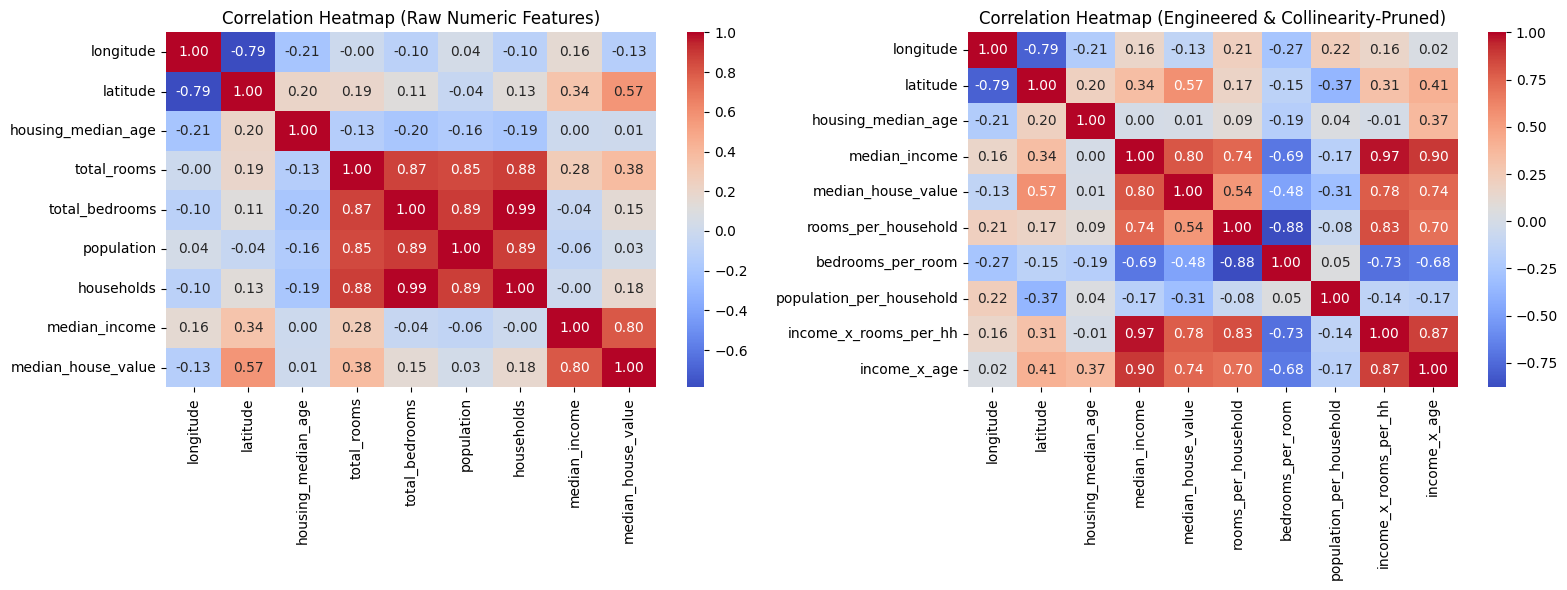

In [2]:
num_cols_raw = df.select_dtypes(include=[np.number]).columns.tolist()

# Median imputation for correlation analysis
df_corr = df.copy()
df_corr[num_cols_raw] = SimpleImputer(strategy="median").fit_transform(df_corr[num_cols_raw])

# Engineer ratios & interaction features and prune collinear raw volume totals
df_corr["rooms_per_household"] = df_corr["total_rooms"] / df_corr["households"].replace(0, np.nan)
df_corr["bedrooms_per_room"] = df_corr["total_bedrooms"] / df_corr["total_rooms"].replace(0, np.nan)
df_corr["population_per_household"] = df_corr["population"] / df_corr["households"].replace(0, np.nan)
df_corr["income_x_rooms_per_hh"] = df_corr["median_income"] * df_corr["rooms_per_household"]
df_corr["income_x_age"] = df_corr["median_income"] * df_corr["housing_median_age"]

raw_volume_cols = ["total_rooms", "total_bedrooms", "population", "households"]
df_corr_pruned = df_corr.drop(columns=raw_volume_cols)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(df_corr[num_cols_raw].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0])
axes[0].set_title("Correlation Heatmap (Raw Numeric Features)")

sns.heatmap(df_corr_pruned.select_dtypes(include=[np.number]).corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Correlation Heatmap (Engineered & Collinearity-Pruned)")
plt.tight_layout()
plt.show()


## 3. Standardize Continuous Variables & Encode Categorical Attributes


In [3]:
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    hh = d["households"].replace(0, np.nan)
    tr = d["total_rooms"].replace(0, np.nan)

    d["rooms_per_household"] = d["total_rooms"] / hh
    d["bedrooms_per_room"] = d["total_bedrooms"] / tr
    d["population_per_household"] = d["population"] / hh
    d["income_x_rooms_per_hh"] = d["median_income"] * d["rooms_per_household"]
    d["income_x_age"] = d["median_income"] * d["housing_median_age"]

    # Drop raw aggregate totals to mitigate multicollinearity
    return d.drop(columns=["total_rooms", "total_bedrooms", "population", "households"])

X = engineer_features(df.drop(columns=["median_house_value"]))
y = df["median_house_value"]

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['longitude', 'latitude', 'housing_median_age', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_rooms_per_hh', 'income_x_age']
Categorical features: ['ocean_proximity']


## 4. Fit OLS, Ridge, and Lasso Models (`GridSearchCV`) & Compare Metrics


In [4]:
param_grid = {"model__alpha": np.logspace(-2, 4, 25)}

# 1. Ordinary Least Squares (OLS)
ols_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])
ols_model.fit(X_train, y_train)
ols_preds = ols_model.predict(X_test)

# 2. Ridge (L2) via GridSearchCV
ridge_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge(max_iter=10000))
])
ridge_grid = GridSearchCV(
    ridge_pipe,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
ridge_grid.fit(X_train, y_train)
ridge_preds = ridge_grid.predict(X_test)

# 3. Lasso (L1) via GridSearchCV
lasso_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=20000))
])
lasso_grid = GridSearchCV(
    lasso_pipe,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
lasso_grid.fit(X_train, y_train)
lasso_preds = lasso_grid.predict(X_test)

def evaluate_model(name, y_true, y_pred, best_alpha=None):
    return {
        "Model": name,
        "Best Alpha": "N/A" if best_alpha is None else round(float(best_alpha), 4),
        "RMSE": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 2),
        "MAE": round(float(mean_absolute_error(y_true, y_pred)), 2),
        "R2": round(float(r2_score(y_true, y_pred)), 4)
    }

metrics_summary = pd.DataFrame([
    evaluate_model("OLS (LinearRegression)", y_test, ols_preds),
    evaluate_model("Ridge (L2)", y_test, ridge_preds, ridge_grid.best_params_["model__alpha"]),
    evaluate_model("Lasso (L1)", y_test, lasso_preds, lasso_grid.best_params_["model__alpha"])
])

metrics_summary


,Model,Best Alpha,RMSE,MAE,R2
0,OLS (LinearRegression),N/A,44778.82,31902.14,0.7909
1,Ridge (L2),10.0,43949.72,31211.01,0.7986
2,Lasso (L1),316.2278,44660.94,31914.66,0.7920


## 5. Plot Predicted vs. Actual Values & Residual Distribution Curves


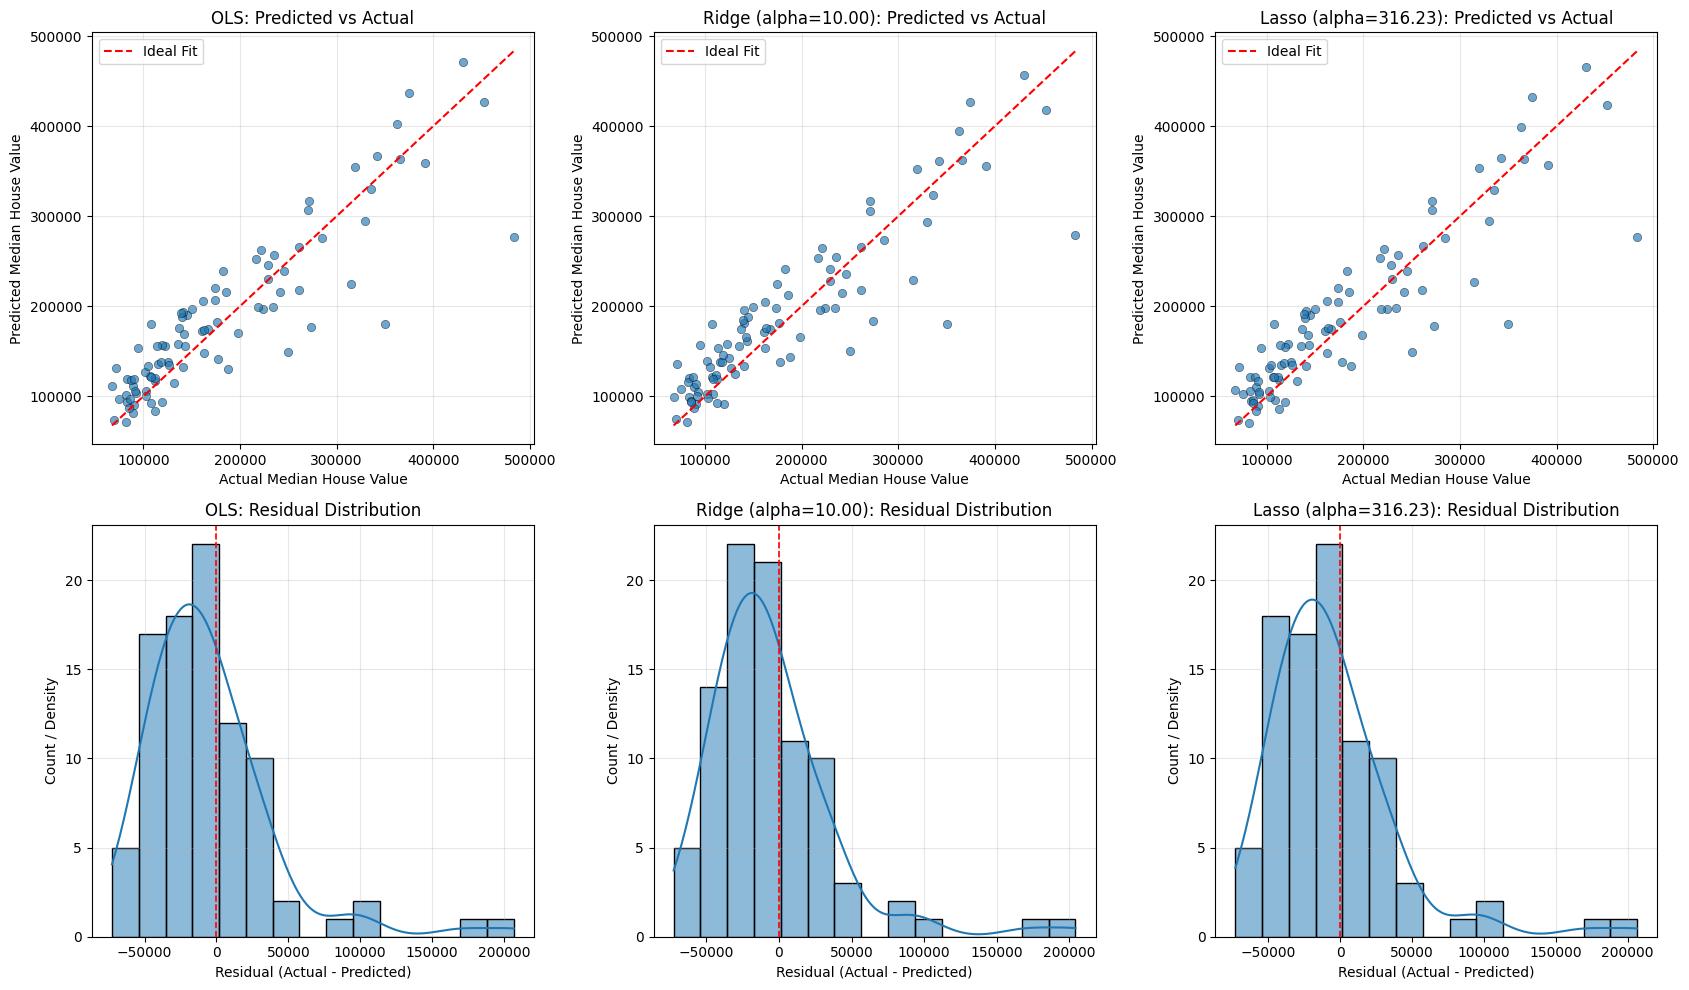

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

model_outputs = [
    ("OLS", ols_preds),
    (f"Ridge (alpha={ridge_grid.best_params_['model__alpha']:.2f})", ridge_preds),
    (f"Lasso (alpha={lasso_grid.best_params_['model__alpha']:.2f})", lasso_preds)
]

for col_idx, (label, y_pred) in enumerate(model_outputs):
    # Top row: Predicted vs Actual
    ax_pred = axes[0, col_idx]
    ax_pred.scatter(y_test, y_pred, alpha=0.65, edgecolors="k", linewidth=0.4)
    line_min = min(y_test.min(), y_pred.min())
    line_max = max(y_test.max(), y_pred.max())
    ax_pred.plot([line_min, line_max], [line_min, line_max], "r--", linewidth=1.5, label="Ideal Fit")
    ax_pred.set_title(f"{label}: Predicted vs Actual")
    ax_pred.set_xlabel("Actual Median House Value")
    ax_pred.set_ylabel("Predicted Median House Value")
    ax_pred.legend()
    ax_pred.grid(True, alpha=0.3)

    # Bottom row: Residual Distribution Curve
    ax_res = axes[1, col_idx]
    residuals = y_test - y_pred
    sns.histplot(residuals, kde=True, bins=15, ax=ax_res)
    ax_res.axvline(0, color="r", linestyle="--", linewidth=1.2)
    ax_res.set_title(f"{label}: Residual Distribution")
    ax_res.set_xlabel("Residual (Actual - Predicted)")
    ax_res.set_ylabel("Count / Density")
    ax_res.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
